# 04. 모델 평가 및 결과 통합 (인기순 · CF · CBF · 하이브리드)
**머신러닝 팀프로젝트 2조 | 음악 아티스트 추천 (Last.fm)**  |  모델 평가 및 결과 통합

---
## 목적
CF·CBF 모델의 결과와 하이브리드 필터링(03 노트북)의 결과를 **하나의 평가 기준**으로 모아 비교하고 통합 결과를 만듭니다. 이 노트북은 모델을 새로 학습하지 않습니다. 03 노트북이 저장한 **추천 결과(CSV)를 불러와 같은 `evaluate()`로 채점**하므로, 모든 모델이 정확히 같은 방식으로 평가됩니다.

## 전체 처리 흐름
```
[1] 데이터·03 결과 로드, 평가 함수 정의
 → [2] 모델별 공식 결과 정리 + 재현성 검증
 → [3] 공통 후보 기준 통합 비교 (주 비교표, 그래프)
 → [4] 통계적 신뢰성: paired bootstrap 95% 신뢰구간
 → [5] 추천 특성: 인기도·새로움, 청취량별 성능, CF·CBF 보완성
 → [6] 안정성: 사용자 재표집 반복
 → [7] 데이터셋 간 일관성, 통합 표·핵심 결과 요약 저장
```

## 설계 방침 (이렇게 구현한 이유)
1. **공식 결과(CF 노트북 조건)를 기준 수치로 삼고, 공통 후보 결과는 보조 기준으로 둡니다.** CF의 공식 결과(A 0.2039, B 0.1462)는 CF 노트북의 평가 조건에서 나온 값이며, 이 노트북은 그 조건을 그대로 따릅니다. 다만 CBF와 하이브리드는 B 전체 조건으로 평가할 수 없으므로(태그와 연결되지 않는 mbid 아티스트 번호), 네 모델의 상대 비교는 후보·사용자·정답이 모두 같은 공통 후보 결과로 보완합니다.
2. **평균 점수만 비교하지 않습니다.** 모델 간 차이가 표본(평가 사용자)의 우연인지 확인하기 위해 신뢰구간과 반복 재표집을 사용합니다. 하이브리드의 개선폭이 작기 때문에 특히 필요한 검증입니다.
3. **정확도 외 특성도 봅니다.** 추천은 정확해도 인기 아티스트에만 몰리면 가치가 떨어집니다. 인기도, 새로움, 청취량별 성능, CF와 CBF의 보완성을 함께 분석합니다.
4. **재현성을 확인합니다.** CF·CBF가 저장한 추천을 이 노트북의 평가 함수로 다시 채점해 공식 결과와 같은 값이 나오는지 확인합니다. 같다면 이 노트북의 평가가 기존 평가와 동일한 방식이라는 근거가 됩니다.

## 비교 원칙
- **공식 결과(표 ①)가 우선 기준입니다.** 각 모델 노트북의 조건으로 계산한 값이며, 특히 CF의 B 수치는 CF 노트북의 조건(B 전체 이력·전체 후보·전체 정답)을 따릅니다. 모델마다 후보와 정답이 달라 표 ①만으로 모델 간 우열은 말하지 않습니다.
- **공통 후보 기준(표 ②)** 은 네 모델의 상대 비교용 보조 기준입니다(후보·Coverage 분모·정답·평가 사용자가 모두 같음). 이 기준의 B CF 수치는 공식 수치와 다릅니다.
- A와 B는 사용자 집단과 후보가 달라 **절대값을 직접 비교하지 않고**, 모델 순위가 일관되는지만 봅니다.

## 0. 설정
그래프 색은 모든 그림에서 모델별로 고정(`COLORS`)하여 그림을 넘나들어도 같은 모델을 쉽게 알아보게 합니다. 한글 폰트는 설치된 것 중 사용 가능한 첫 번째를 선택하며, 마이너스 기호가 깨지지 않도록 `axes.unicode_minus`를 끕니다. `SEED = 42`는 부트스트랩과 재표집의 난수를 고정해 결과를 재현하기 위한 값입니다.

In [63]:
# 0. 설정
import os, io, re, json, zipfile, pathlib, hashlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
warnings.filterwarnings('ignore')

SEED = 42
TOPK = 10
# ---- 경로 설정 --------------------------------------------------------------------------
BASE_DIR = pathlib.Path.cwd()          # 작업 폴더(노트북이 있는 폴더). 다른 위치를 쓰려면 직접 지정: pathlib.Path('/path/to/ml_project')
ZIP_PATH = None                        # 전처리 ZIP 경로를 직접 지정하려면 입력 (None이면 BASE_DIR, BASE_DIR/data 에서 ZIP을 자동 탐색)
OUT = BASE_DIR / 'integration_outputs'; OUT.mkdir(parents=True, exist_ok=True)

# 한글 폰트: 설치된 것 중 첫 번째 사용 (Windows: Malgun Gothic, macOS: AppleGothic). 없으면 한글이 깨질 수 있습니다.
_installed = {f.name for f in font_manager.fontManager.ttflist}
for _f in ['NanumGothic', 'Malgun Gothic', 'AppleGothic', 'Noto Sans CJK KR', 'NanumBarunGothic']:
    if _f in _installed:
        plt.rcParams['font.family'] = _f; break
else:
    print('경고: 한글 폰트를 찾지 못했습니다. 그래프의 한글이 깨질 수 있습니다.')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10, 'axes.unicode_minus': False})

KEYS = ['pop', 'cf', 'cbf', 'hybrid']
LABEL = {'pop': 'Popularity', 'cf': 'CF', 'cbf': 'CBF', 'hybrid': 'Hybrid'}
MODELS = [LABEL[k] for k in KEYS]
COLORS = {'Popularity': '#8c8c8c', 'CF': '#1f77b4', 'CBF': '#e07b00', 'Hybrid': '#2a9d5c'}      # 모든 그래프에서 모델별 색 고정

def get_dir(name, required):
    """BASE_DIR/name 폴더를 반환합니다. 없으면 필수 폴더는 중단, 선택 폴더는 None(관련 표·검증 건너뜀)."""
    d = BASE_DIR / name
    if d.exists(): return d
    assert not required, f'필수 폴더 {d} 가 없습니다. 03_Hybrid_Filtering 노트북을 먼저 실행하세요.'
    print(f'[{name}] 없음 → 관련 표·검증은 건너뜁니다.'); return None

HYB_DIR = get_dir('hybrid_outputs', True)
CF_DIR = get_dir('cf_outputs', False)
CBF_DIR = get_dir('cbf_outputs', False)
print('hybrid_outputs:', HYB_DIR, '| cf_outputs:', CF_DIR, '| cbf_outputs:', CBF_DIR)

hybrid_outputs: ./hybrid_outputs | cf_outputs: ./cf_outputs | cbf_outputs: ./cbf_outputs


## 1. 데이터와 03 결과 로드

In [64]:
# 1-1. 전처리 ZIP · 03 산출물
def find_zip():
    """전처리 ZIP 경로를 반환합니다. ZIP_PATH가 없으면 BASE_DIR, BASE_DIR/data 에서 ZIP을 찾습니다(결과물 ZIP 제외)."""
    if ZIP_PATH is not None:
        p = pathlib.Path(ZIP_PATH); assert p.exists(), f'{p} 파일이 없습니다.'; return p
    hits = [p for d in (BASE_DIR, BASE_DIR / 'data') if d.exists() for p in d.glob('*.zip') if not p.stem.endswith('_outputs')]
    assert len(hits) == 1, f'전처리 ZIP을 정확히 1개 찾아야 합니다. 찾은 파일: {[str(h) for h in hits]} → ZIP_PATH를 직접 지정하세요.'
    return hits[0]

ZIP_FILE = find_zip()
print('전처리 ZIP:', ZIP_FILE, '| SHA256:', hashlib.sha256(ZIP_FILE.read_bytes()).hexdigest()[:16], '...')
Z = zipfile.ZipFile(ZIP_FILE); NAMES = set(Z.namelist())
rd = lambda f: pd.read_csv(Z.open(f), encoding='utf-8-sig', low_memory=False)
a = {s: rd(f'Lastfm.2k-a/{s}.csv') for s in ('train', 'validation', 'test')}
a_art = rd('Lastfm.2k-a/artists.csv')
A_HIST = pd.concat([a['train'], a['validation']], ignore_index=True)
A_USERS = sorted(A_HIST.user_id.unique())

HCFG = json.loads((HYB_DIR / 'config.json').read_text(encoding='utf-8'))
print('하이브리드 설정:', HCFG['hybrid'])
print('CF 설정:', HCFG['cf'], '| CBF 설정:', HCFG['cbf'])

def load_recs(tag):
    return {k: pd.read_csv(HYB_DIR / f'{tag}_test_recs_common_{k}.csv') for k in KEYS}

CTX = {}
# --- Dataset A
CTX['A'] = dict(title='Dataset A (Last.fm 2K, 내부 평가)', hist=A_HIST, truth=a['test'], users=A_USERS,
                cand=pd.read_csv(HYB_DIR / 'A_common_candidates.csv').artist_id.tolist(), recs=load_recs('A'))
# --- Dataset B (03에서 B를 실행했고 ZIP에 B 파일이 있을 때)
B_NEED = ['Lastfm.360k-b/content_external_candidates/train.csv', 'Lastfm.360k-b/content_external_candidates/validation.csv', 'Lastfm.360k-b/content_external_candidates/test.csv']
if HCFG.get('ran_B') and set(B_NEED) <= NAMES and (HYB_DIR / 'B_eval_users.csv').exists():
    b_hist = pd.concat([rd('Lastfm.360k-b/content_external_candidates/train.csv'), rd('Lastfm.360k-b/content_external_candidates/validation.csv')], ignore_index=True)    # 03과 같은 B 관측 이력(외부 후보 파일, A 번호)
    b_users = pd.read_csv(HYB_DIR / 'B_eval_users.csv').user_id.tolist()
    b_test = rd('Lastfm.360k-b/content_external_candidates/test.csv'); b_test = b_test[b_test.user_id.isin(b_users)]
    CTX['B'] = dict(title='Dataset B (Last.fm 360K, 외부 평가)', hist=b_hist, truth=b_test, users=b_users,
                    cand=pd.read_csv(HYB_DIR / 'B_common_candidates.csv').artist_id.tolist(), recs=load_recs('B'))
else:
    print('B 결과 또는 B 파일이 없어 Dataset B 분석은 건너뜁니다.')
# --- Dataset B 공식 조건(CF 노트북 기준): CF·인기순 추천과 B 전체 데이터
B_OFF = None
if HCFG.get('ran_B_official') and (HYB_DIR / 'B_test_recs_official_cf.csv').exists():
    _bf = {s_: rd(f'Lastfm.360k-b/{s_}.csv') for s_ in ('train', 'validation', 'test')}
    B_OFF = dict(hist=pd.concat([_bf['train'], _bf['validation']], ignore_index=True), truth=_bf['test'],
                 recs={'CF': pd.read_csv(HYB_DIR / 'B_test_recs_official_cf.csv'), 'Popularity': pd.read_csv(HYB_DIR / 'B_test_recs_official_pop.csv')})
    B_OFF['users'] = sorted(B_OFF['hist'].user_id.unique())
    print(f"B 공식 조건: 평가 사용자 {len(B_OFF['users']):,}명 | 정답 {len(B_OFF['truth']):,}행")
for tag, c in CTX.items():
    print(f"{tag}: 평가 사용자 {len(c['users']):,}명 | 공통 후보 {len(c['cand']):,}개 | 정답 {len(c['truth']):,}행 | 모델 {list(c['recs'])}")

전처리 ZIP: ./data/전처리데이터.zip | SHA256: 9ef1b2df065009cc ...
하이브리드 설정: {'method': 'weighted RRF', 'rrf_c': 60, 'pool': 50, 'w_cf': 0.9, 'w_grid': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], 'selection': 'Dataset A validation NDCG@10 (tie: recall10, precision10, smaller w)'}
CF 설정: {'k': 30, 'weight': 'log'} | CBF 설정: {'tf_mode': 'raw', 'weight_mode': 'uniform'}
B 공식 조건: 평가 사용자 9,997명 | 정답 93,948행
A: 평가 사용자 1,877명 | 공통 후보 9,444개 | 정답 18,540행 | 모델 ['pop', 'cf', 'cbf', 'hybrid']
B: 평가 사용자 9,931명 | 공통 후보 8,161개 | 정답 64,966행 | 모델 ['pop', 'cf', 'cbf', 'hybrid']


### 평가 함수
CF·CBF 노트북과 동일한 `evaluate()`를 사용합니다. Precision@10은 추천 10개 중 정답의 비율, Recall@10은 숨겨 둔 정답 중 맞힌 비율이고, NDCG@10은 정답이 상위에 놓일수록 높은 점수를 주는 순위 지표입니다. Catalog Coverage는 추천된 서로 다른 아티스트 수를 후보 수로 나눈 값입니다. 수식은 03 노트북 2-3절에 정리했습니다.

In [65]:
# 1-2. 평가 함수 (CF·CBF 노트북 공통, 수정 없음)
def evaluate(recs, truth, users, candidate_ids, k=10):
    users = list(users); truth_by = truth.groupby('user_id').artist_id.agg(set).to_dict()
    pred_by = recs.sort_values('rank').groupby('user_id').artist_id.agg(list).to_dict() if len(recs) else {}
    cand = set(candidate_ids); discount = 1 / np.log2(np.arange(2, k + 2))
    records = []
    for u in users:
        gt = truth_by.get(u, set()); pred = pred_by.get(u, [])
        assert len(gt) > 0, f'{u}: 정답 없는 사용자'
        hit = np.array([int(x in gt) for x in pred[:k]], dtype=float)
        dcg = float((hit * discount[:len(hit)]).sum())
        reachable = gt & cand
        records.append({'user_id': u, 'precision10': float(hit.sum() / k),
           'recall10': float(hit.sum() / len(gt)),
           'ndcg10': float(dcg / discount[:min(k, len(gt))].sum()),
           'conditional_recall10': float(hit.sum() / len(reachable)) if reachable else np.nan,
           'conditional_ndcg10': float(dcg / discount[:min(k, len(reachable))].sum()) if reachable else np.nan,
           'gt_count': len(gt), 'reachable_gt': len(reachable), 'hits': int(hit.sum()), 'recommendations': len(pred)})
    per = pd.DataFrame(records)
    summary = {c: float(per[c].mean()) for c in ['precision10', 'recall10', 'ndcg10', 'conditional_recall10', 'conditional_ndcg10']}
    summary.update({'catalog_coverage': float(recs.artist_id.nunique() / len(cand)),
       'reachable_gt_fraction': float(per.reachable_gt.sum() / per.gt_count.sum()),
       'users': len(users), 'users_with_reachable_gt': int((per.reachable_gt > 0).sum()),
       'recommended_users': int((per.recommendations > 0).sum()), 'catalog_size': len(cand)})
    return summary, per

_s, _ = evaluate(pd.DataFrame({'user_id': ['u'], 'artist_id': [101], 'rank': [1], 'score': [1.]}),
                 pd.DataFrame({'user_id': ['u'], 'artist_id': [101]}), ['u'], [101, 102], 10)
assert np.isclose(_s['precision10'], .1) and np.isclose(_s['recall10'], 1.) and np.isclose(_s['ndcg10'], 1.)
print('evaluate() 단위 테스트 통과')

evaluate() 단위 테스트 통과


## 2. 모델별 공식 결과 (표 ①) 와 재현성 검증
CF·CBF 노트북이 저장한 `evaluation_summary.csv`를 그대로 불러옵니다. 이 표는 **각 모델의 노트북이 자체 평가 조건으로 계산한 값(공식 결과)** 이므로 후보 집합(Coverage 분모)과 B의 정답 기준이 모델마다 다릅니다.
- CF·인기순: A는 관측된 아티스트 전체가 후보이고, B는 B 전체 데이터를 정답 기준으로 사용
- CBF: A는 태그 있는 아티스트(10,425개)가 후보, B는 공통 후보로 제한한 정답

따라서 이 표는 **우선 기준이 되는 모델별 공식 결과**입니다. CF의 B 수치는 CF 노트북의 조건을 따르며, 모델 간 상대 비교는 3절의 공통 후보 기준 표(보조 기준)로 보완합니다.

**재현성 검증.** 03 노트북이 CF 노트북 조건으로 만든 B 공식 추천(CF·인기순)도 같은 방식으로 다시 채점하여 공식 B 수치와 맞는지 확인합니다. CF·CBF가 저장한 A Test 추천 CSV를 이 노트북의 `evaluate()`로 다시 채점해 공식 결과의 지표(Precision, Recall, NDCG, Coverage)와 $10^{-6}$ 이내로 같은지 확인합니다. 후보 집합은 각 모델이 원래 사용한 것(CF: 관측된 전체 아티스트, CBF: 태그 있는 아티스트)으로 맞춥니다.

In [66]:
# 2-1. 표 ① 모델별 공식 결과
SHOW = ['dataset', 'model', 'precision10', 'recall10', 'ndcg10', 'catalog_coverage', 'catalog_size', 'reachable_gt_fraction', 'users']
rows1 = []
if CF_DIR and (CF_DIR / 'evaluation_summary.csv').exists():
    cf_sum = pd.read_csv(CF_DIR / 'evaluation_summary.csv')
    for r in cf_sum.itertuples():
        rows1.append({**r._asdict(), 'model': 'Popularity' if 'Popularity' in r.model else 'CF', 'source': 'CF 노트북'})
if CBF_DIR and (CBF_DIR / 'evaluation_summary.csv').exists():
    cbf_sum = pd.read_csv(CBF_DIR / 'evaluation_summary.csv')
    for r in cbf_sum[cbf_sum.dataset.isin(['A_test', 'B_test'])].itertuples():
        rows1.append({**r._asdict(), 'model': 'CBF', 'source': 'CBF 노트북'})
if rows1:
    tab1 = pd.DataFrame(rows1)
    tab1 = tab1.reindex(columns=['dataset', 'model', 'precision10', 'recall10', 'ndcg10', 'catalog_coverage', 'catalog_size', 'reachable_gt_fraction', 'users', 'source'])
    tab1['model'] = pd.Categorical(tab1.model, MODELS, ordered=True); tab1 = tab1.sort_values(['dataset', 'model']).reset_index(drop=True)
    print('[표 ①] 모델별 공식 결과 (우선 기준: 모델 노트북의 평가 조건, CF의 B 수치는 CF 노트북 조건 — 모델 간 직접 비교용 아님)')
    display(tab1.round(4)); tab1.round(6).to_csv(OUT / 'table1_official_results.csv', index=False)
else:
    tab1 = None; print('evaluation_summary.csv가 없어 표 ①을 건너뜁니다.')

[표 ①] 모델별 공식 결과 (우선 기준: 모델 노트북의 평가 조건, CF의 B 수치는 CF 노트북 조건 — 모델 간 직접 비교용 아님)


,dataset,model,precision10,recall10,ndcg10,catalog_coverage,catalog_size,reachable_gt_fraction,users,source
0,A_test,Popularity,0.0669,0.0685,0.0783,0.0017,15384,0.8727,1877,CF 노트북
1,A_test,CF,0.1663,0.1692,0.2039,0.0471,15384,0.8727,1877,CF 노트북
2,A_test,CBF,0.0973,0.0992,0.1135,0.2296,10425,0.9092,1877,CBF 노트북
3,B_test,Popularity,0.0322,0.0342,0.0394,0.0005,48981,0.9376,9997,CF 노트북
4,B_test,CF,0.1165,0.1249,0.1462,0.0645,48981,0.9376,9997,CF 노트북
5,B_test,CBF,0.0554,0.0878,0.0831,0.4011,9282,1.0000,9931,CBF 노트북


In [67]:
# 2-2. 재현성 검증: 저장된 추천 CSV를 다시 평가해 공식 결과와 대조
def reproduce(name, rec_path, cand, summary_row):
    recs = pd.read_csv(rec_path)
    s, _ = evaluate(recs, a['test'], A_USERS, cand)
    diffs = {m: s[m] - float(summary_row[m]) for m in ['precision10', 'recall10', 'ndcg10', 'catalog_coverage']}
    ok = all(abs(d) < 1e-6 for d in diffs.values())
    print(f"{name}: {'일치' if ok else '불일치 — 확인 필요'} | " + ' '.join(f'{m[:7]} 차이 {d:+.2e}' for m, d in diffs.items()))
    return ok

repro = {}
eligible_ids = sorted(a_art.loc[a_art.content_eligible.eq(1), 'artist_id'])
if CF_DIR and (CF_DIR / 'A_test_CF_recommendations.csv').exists() and rows1:
    row = cf_sum[(cf_sum.dataset == 'A_test') & cf_sum.model.str.contains('CF')].iloc[0]
    repro['CF'] = reproduce('CF  (A test)', CF_DIR / 'A_test_CF_recommendations.csv', sorted(A_HIST.artist_id.unique()), row)
if CBF_DIR and (CBF_DIR / 'A_test_recommendations.csv').exists() and rows1:
    row = cbf_sum[cbf_sum.dataset == 'A_test'].iloc[0]
    repro['CBF'] = reproduce('CBF (A test)', CBF_DIR / 'A_test_recommendations.csv', eligible_ids, row)
# B 공식 조건: 03이 만든 CF·인기순 추천을 다시 채점해 CF 노트북의 B 공식 값과 비교
if B_OFF is not None and CF_DIR and (CF_DIR / 'evaluation_summary.csv').exists():
    _ref = pd.read_csv(CF_DIR / 'evaluation_summary.csv'); _ref = _ref[_ref.dataset == 'B_test']
    for m_ in ['CF', 'Popularity']:
        _r = _ref[_ref.model.str.contains(m_)]
        if not len(_r): continue
        _cand = sorted(B_OFF['hist'].artist_id.unique())
        _s, _ = evaluate(B_OFF['recs'][m_], B_OFF['truth'], B_OFF['users'], _cand)
        _d = {x: _s[x] - float(_r.iloc[0][x]) for x in ['precision10', 'recall10', 'ndcg10', 'catalog_coverage']}
        _ok = all(abs(v) < 1e-6 for v in _d.values())
        print(f"{m_:10s} (B test, 공식 조건): {'일치' if _ok else '불일치 — 확인 필요'} | NDCG@10 {_s['ndcg10']:.6f} (CF 노트북 {float(_r.iloc[0].ndcg10):.6f})")
        repro[f'{m_} (B)'] = _ok
if not repro: print('저장된 추천 CSV가 없어 재현성 검증을 건너뜁니다.')

CF  (A test): 일치 | precisi 차이 +8.33e-17 recall1 차이 +5.55e-17 ndcg10 차이 +5.55e-17 catalog 차이 +1.39e-17
CBF (A test): 일치 | precisi 차이 +4.16e-17 recall1 차이 +8.33e-17 ndcg10 차이 +8.33e-17 catalog 차이 +8.33e-17
CF         (B test, 공식 조건): 일치 | NDCG@10 0.146210 (CF 노트북 0.146210)
Popularity (B test, 공식 조건): 일치 | NDCG@10 0.039385 (CF 노트북 0.039385)


## 3. 공통 후보 기준 통합 비교 (표 ②) — 상대 비교용 보조 기준
03 노트북이 만든 4개 모델의 Top-10을 **같은 후보 집합·같은 정답·같은 평가 사용자**로 평가합니다. CBF와 하이브리드까지 포함한 네 모델의 상대 비교는 이 표를 근거로 하며, 절대 수치(특히 B의 CF)는 표 ①의 공식 결과가 우선합니다.

In [68]:
# 3-1. 표 ② 평가
cols = ['precision10', 'recall10', 'ndcg10', 'catalog_coverage', 'conditional_recall10', 'conditional_ndcg10', 'reachable_gt_fraction', 'catalog_size', 'users']
RES = {}
for tag, c in CTX.items():
    rows, per = [], {}
    for k in KEYS:
        s, p = evaluate(c['recs'][k], c['truth'], c['users'], c['cand']); per[LABEL[k]] = p
        rows.append({'model': LABEL[k], **s})
    RES[tag] = dict(tab=pd.DataFrame(rows).set_index('model')[cols], per=per)
    print(f"\n[표 ②] {c['title']} — 공통 후보 {len(c['cand']):,}개, 평가 사용자 {len(c['users']):,}명")
    display(RES[tag]['tab'].round(4))
    RES[tag]['tab'].round(6).to_csv(OUT / f'table2_{tag}_common.csv')


[표 ②] Dataset A (Last.fm 2K, 내부 평가) — 공통 후보 9,444개, 평가 사용자 1,877명


,precision10,recall10,ndcg10,catalog_coverage,conditional_recall10,conditional_ndcg10,reachable_gt_fraction,catalog_size,users
model,,,,,,,,,
Popularity,0.0669,0.0685,0.0783,0.0028,0.0746,0.0825,0.8516,9444,1877
CF,0.1663,0.1692,0.2039,0.0763,0.1897,0.2181,0.8516,9444,1877
CBF,0.0946,0.0965,0.1106,0.2445,0.1143,0.1220,0.8516,9444,1877
Hybrid,0.1701,0.1733,0.2095,0.0840,0.1948,0.2246,0.8516,9444,1877



[표 ②] Dataset B (Last.fm 360K, 외부 평가) — 공통 후보 8,161개, 평가 사용자 9,931명


,precision10,recall10,ndcg10,catalog_coverage,conditional_recall10,conditional_ndcg10,reachable_gt_fraction,catalog_size,users
model,,,,,,,,,
Popularity,0.0313,0.0448,0.0456,0.0027,0.0449,0.0457,0.9973,8161,9931
CF,0.1082,0.1676,0.1690,0.3034,0.1680,0.1692,0.9973,8161,9931
CBF,0.0564,0.0894,0.0847,0.4374,0.0896,0.0849,0.9973,8161,9931
Hybrid,0.1111,0.1727,0.1718,0.3165,0.1731,0.1720,0.9973,8161,9931


In [69]:
# 3-2. 표 ① 공식 값 vs 표 ② 공통 후보 값 (A)
if tab1 is not None and 'A' in RES:
    off = tab1[tab1.dataset == 'A_test'].set_index('model')[['ndcg10', 'catalog_coverage']].add_suffix('(공식)')
    com = RES['A']['tab'][['ndcg10', 'catalog_coverage']].add_suffix('(공통)')
    display(off.join(com, how='outer').round(4))
    print('A: 공통 후보 기준은 CBF 후보로 추천 범위를 맞춘 것이라 CF·인기순 값이 공식 값과 거의 같고, Coverage 분모만 달라집니다.')
if tab1 is not None and 'B' in RES:
    off = tab1[tab1.dataset == 'B_test'].set_index('model')[['ndcg10', 'catalog_coverage', 'catalog_size', 'users']].add_suffix('(공식)')
    com = RES['B']['tab'][['ndcg10', 'catalog_coverage', 'catalog_size', 'users']].add_suffix('(공통)')
    display(off.join(com, how='outer').round(4))
    print('B: CF·인기순의 공식 값은 B 전체 이력·전체 후보·전체 정답 기준이고, 공통 후보 값은 외부 후보 파일 기준이라 수치가 다릅니다. 기준 수치는 공식 값입니다.')

,ndcg10(공식),catalog_coverage(공식),ndcg10(공통),catalog_coverage(공통)
model,,,,
CBF,0.1135,0.2296,0.1106,0.2445
CF,0.2039,0.0471,0.2039,0.0763
Hybrid,NaN,NaN,0.2095,0.0840
Popularity,0.0783,0.0017,0.0783,0.0028


A: 공통 후보 기준은 CBF 후보로 추천 범위를 맞춘 것이라 CF·인기순 값이 공식 값과 거의 같고, Coverage 분모만 달라집니다.


,ndcg10(공식),catalog_coverage(공식),catalog_size(공식),users(공식),ndcg10(공통),catalog_coverage(공통),catalog_size(공통),users(공통)
model,,,,,,,,
CBF,0.0831,0.4011,9282.0,9931.0,0.0847,0.4374,8161,9931
CF,0.1462,0.0645,48981.0,9997.0,0.1690,0.3034,8161,9931
Hybrid,NaN,NaN,NaN,NaN,0.1718,0.3165,8161,9931
Popularity,0.0394,0.0005,48981.0,9997.0,0.0456,0.0027,8161,9931


B: CF·인기순의 공식 값은 B 전체 이력·전체 후보·전체 정답 기준이고, 공통 후보 값은 외부 후보 파일 기준이라 수치가 다릅니다. 기준 수치는 공식 값입니다.


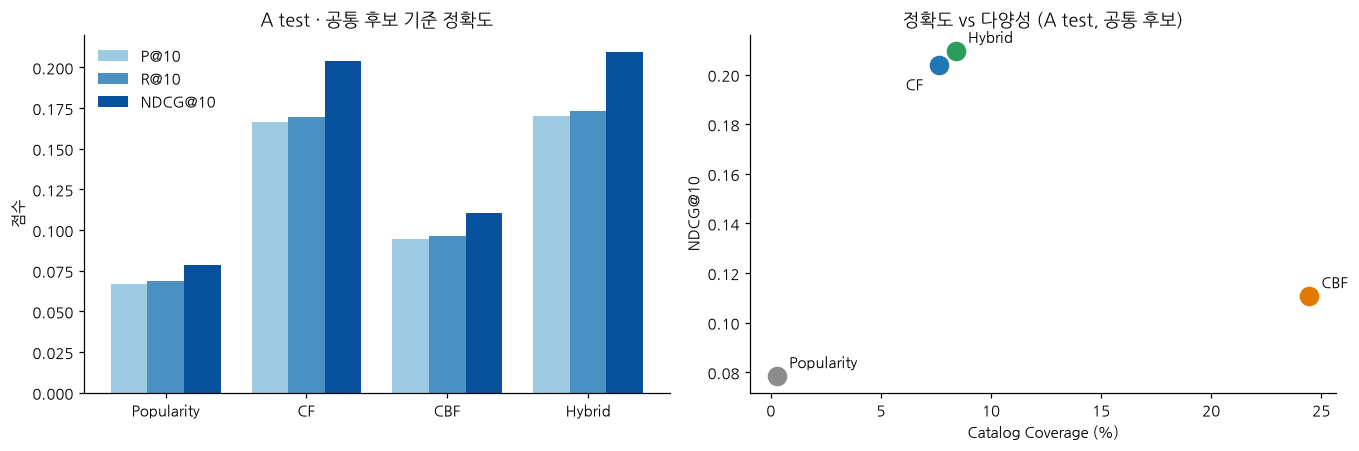

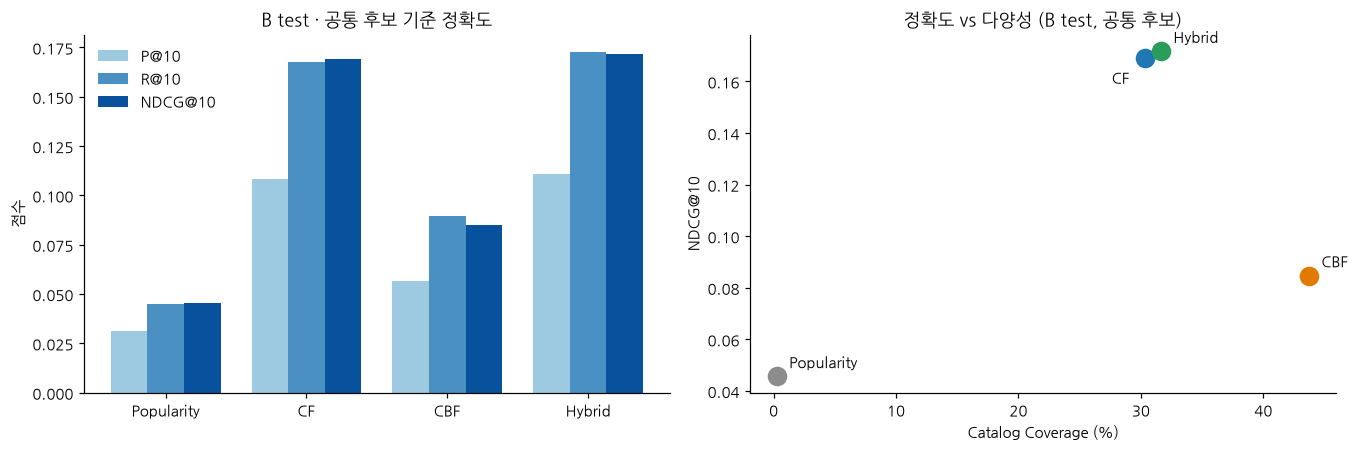

In [70]:
# 3-3. 그래프 1: 정확도 비교 · 정확도 vs 다양성
for tag, c in CTX.items():
    T = RES[tag]['tab']
    fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.2))
    x = np.arange(len(MODELS)); w_ = 0.26
    for i, (m, lab, col) in enumerate([('precision10', 'P@10', '#9ecae1'), ('recall10', 'R@10', '#4a90c2'), ('ndcg10', 'NDCG@10', '#08519c')]):
        axs[0].bar(x + (i - 1) * w_, [T.loc[n, m] for n in MODELS], w_, label=lab, color=col)
    axs[0].set_xticks(x, MODELS); axs[0].set_ylabel('점수'); axs[0].set_title(f'{tag} test · 공통 후보 기준 정확도'); axs[0].legend(frameon=False)
    for n in MODELS:
        axs[1].scatter(T.loc[n, 'catalog_coverage'] * 100, T.loc[n, 'ndcg10'], s=140, color=COLORS[n], zorder=3)
        axs[1].annotate(n, (T.loc[n, 'catalog_coverage'] * 100, T.loc[n, 'ndcg10']), textcoords='offset points',
                        xytext=((-10, -16) if n == 'CF' else (8, 6)), ha=('right' if n == 'CF' else 'left'))   # CF와 Hybrid 점이 겹쳐도 라벨이 겹치지 않게
    axs[1].set(xlabel='Catalog Coverage (%)', ylabel='NDCG@10', title=f'정확도 vs 다양성 ({tag} test, 공통 후보)')
    plt.tight_layout(); plt.savefig(OUT / f'fig1_accuracy_vs_coverage_{tag}.png', dpi=160); plt.show()

## 4. 통계적 신뢰성 (paired bootstrap)
모델 A와 B의 사용자별 점수 차이 $d_u = x_u^{A} - x_u^{B}$를 사용자 단위로 복원추출(2,000회)해 평균 차이의 분포를 만들고, 2.5%와 97.5% 분위수를 95% 신뢰구간으로 사용합니다.
$$\bar d^{*(b)}=\frac{1}{n}\sum_{u\in S^{*(b)}} d_u,\qquad b=1,\dots,2000$$
같은 사용자의 점수를 짝지어($\text{paired}$) 차이를 구하는 이유는 사용자마다 추천 난이도가 다르기 때문입니다. 짝지으면 사용자 간 난이도 차이는 상쇄되고 모델 간 차이만 남아 더 정밀하게 비교할 수 있습니다.
구간이 0을 포함하지 않으면 두 모델의 차이가 우연이라고 보기 어렵습니다(평가 사용자 표본에 대한 불확실성만 반영합니다).


[A] 모델 간 차이의 95% 신뢰구간


,비교,지표,평균 차이,CI 하한,CI 상한,유의(0 미포함)
0,CF − Popularity,precision10,0.0994,0.0939,0.1047,True
1,CF − Popularity,recall10,0.1007,0.0951,0.1060,True
2,CF − Popularity,ndcg10,0.1256,0.1188,0.1325,True
3,CBF − Popularity,precision10,0.0278,0.0222,0.0331,True
4,CBF − Popularity,recall10,0.0280,0.0219,0.0335,True
5,CBF − Popularity,ndcg10,0.0323,0.0253,0.0392,True
6,CF − CBF,precision10,0.0717,0.0657,0.0778,True
7,CF − CBF,recall10,0.0727,0.0665,0.0792,True
8,CF − CBF,ndcg10,0.0934,0.0861,0.1013,True
9,Hybrid − CF,precision10,0.0038,0.0017,0.0061,True


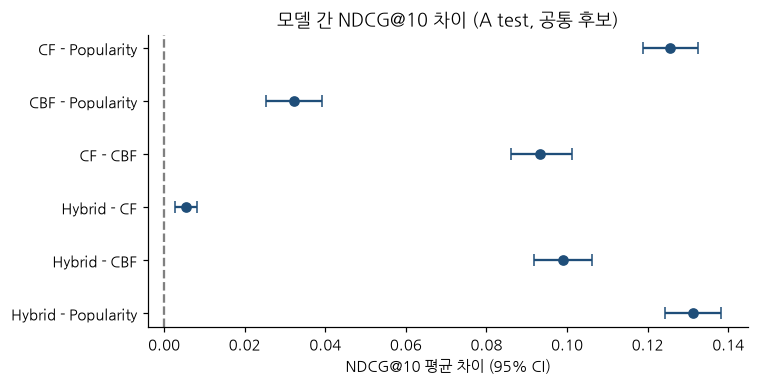


[B] 모델 간 차이의 95% 신뢰구간


,비교,지표,평균 차이,CI 하한,CI 상한,유의(0 미포함)
0,CF − Popularity,precision10,0.0769,0.0748,0.0790,True
1,CF − Popularity,recall10,0.1228,0.1191,0.1262,True
2,CF − Popularity,ndcg10,0.1233,0.1196,0.1268,True
3,CBF − Popularity,precision10,0.0251,0.0231,0.0270,True
4,CBF − Popularity,recall10,0.0446,0.0413,0.0477,True
5,CBF − Popularity,ndcg10,0.0391,0.0359,0.0422,True
6,CF − CBF,precision10,0.0519,0.0499,0.0538,True
7,CF − CBF,recall10,0.0782,0.0749,0.0815,True
8,CF − CBF,ndcg10,0.0842,0.0808,0.0874,True
9,Hybrid − CF,precision10,0.0029,0.0021,0.0037,True


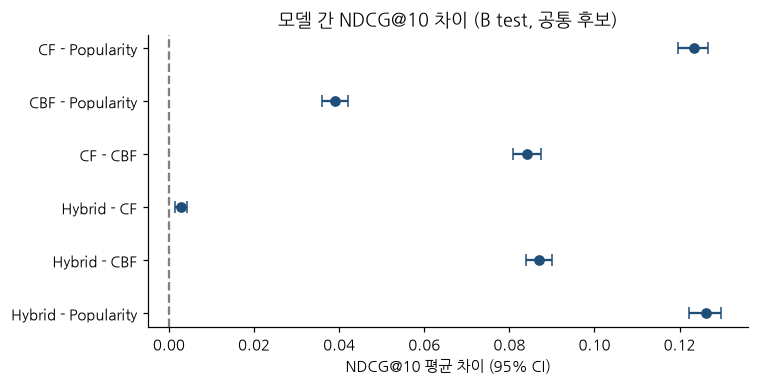

In [71]:
# 4-1. bootstrap 95% CI
def paired_bootstrap(a_, b_, n_boot=2000, seed=SEED):
    """a_, b_: 같은 사용자 순서의 사용자별 점수. 반환: (평균 차이, 95% CI 하한, 상한)"""
    d = (a_ - b_).to_numpy(); rng = np.random.default_rng(seed)
    means = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n_boot)])
    return d.mean(), *np.percentile(means, [2.5, 97.5])

PAIRS = [('CF', 'Popularity'), ('CBF', 'Popularity'), ('CF', 'CBF'), ('Hybrid', 'CF'), ('Hybrid', 'CBF'), ('Hybrid', 'Popularity')]
for tag in CTX:
    per = RES[tag]['per']; ci_rows = []
    for x_, y_ in PAIRS:
        for m in ['precision10', 'recall10', 'ndcg10']:
            mean, lo, hi = paired_bootstrap(per[x_].set_index('user_id')[m], per[y_].set_index('user_id')[m])
            ci_rows.append({'비교': f'{x_} − {y_}', '지표': m, '평균 차이': mean, 'CI 하한': lo, 'CI 상한': hi, '유의(0 미포함)': bool((lo > 0) or (hi < 0))})
    RES[tag]['ci'] = pd.DataFrame(ci_rows)
    print(f'\n[{tag}] 모델 간 차이의 95% 신뢰구간'); display(RES[tag]['ci'].round(4))
    RES[tag]['ci'].round(6).to_csv(OUT / f'table3_{tag}_bootstrap_ci.csv', index=False)
    sub = RES[tag]['ci'][RES[tag]['ci']['지표'] == 'ndcg10'].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.errorbar(sub['평균 차이'], range(len(sub)), xerr=[sub['평균 차이'] - sub['CI 하한'], sub['CI 상한'] - sub['평균 차이']], fmt='o', color='#1f4e79', capsize=4)
    ax.axvline(0, color='gray', ls='--'); ax.set_yticks(range(len(sub)), [t.replace('−', '-') for t in sub['비교']]); ax.invert_yaxis()
    ax.set_xlabel('NDCG@10 평균 차이 (95% CI)'); ax.set_title(f'모델 간 NDCG@10 차이 ({tag} test, 공통 후보)')
    plt.tight_layout(); plt.savefig(OUT / f'fig2_ndcg_diff_ci_{tag}.png', dpi=160); plt.show()

## 5. 추천 특성 분석
태그 기반(CBF)은 비주류 아티스트를, 청취 기반(CF)과 인기순은 인기 아티스트를 추천하는 경향이 있다는 가설을 확인하고, 하이브리드가 그 사이 어디에 놓이는지 봅니다. 인기도는 **관측 이력(train+validation)** 에서 아티스트를 들은 서로 다른 사용자 수이며 Test는 쓰지 않습니다.

- **헤드 비율**: 공통 후보 중 청취자가 가장 많은 상위 100개 아티스트가 추천에서 차지하는 비율입니다. 높을수록 인기 편향이 큽니다.
- **새로움**: 추천 아티스트의 평균 $-\log_2\!\big(\frac{\ell_i+1}{N+1}\big)$입니다($\ell_i$는 청취자 수, $N$은 전체 사용자 수). 덜 알려진 아티스트를 추천할수록 커집니다. CF·CBF 노트북과 같은 정의를 사용합니다.
- **청취량 3분위**: 사용자당 관측 아티스트 수는 대부분 비슷해 구분이 어려우므로 총 청취 횟수로 3등분하여, 이력이 적은 사용자(콜드스타트에 가까운 경우)에서 모델별 성능이 어떻게 달라지는지 봅니다.
- **보완성**: 두 모델이 서로 다른 정답을 맞히는지 보기 위해 추천 목록의 Jaccard 유사도와, 적중한 정답이 '둘 다 / CF만 / CBF만'에 속하는 비율을 계산합니다. $\text{Jaccard}=\frac{|L_{CF}\cap L_{CBF}|}{|L_{CF}\cup L_{CBF}|}$이 작고 'CBF만' 적중이 존재하면 결합의 여지가 있다는 뜻입니다.


[A] 추천 아티스트의 인기도 · 새로움


,추천 중 서로 다른 아티스트 수,추천 아티스트 청취자 수 중앙값,헤드(상위100) 비율,새로움(평균 -log2((l+1)/(N+1)))
model,,,,
Popularity,26,348.0,1.000,2.417
CF,721,175.0,0.741,3.689
CBF,2309,27.0,0.225,6.374
Hybrid,793,159.0,0.712,3.786


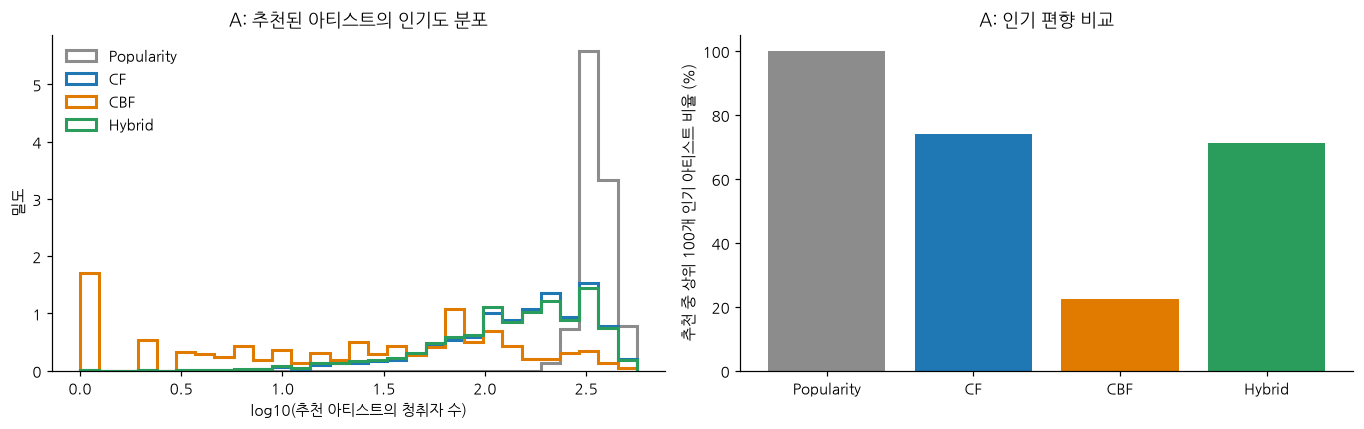


[B] 추천 아티스트의 인기도 · 새로움


,추천 중 서로 다른 아티스트 수,추천 아티스트 청취자 수 중앙값,헤드(상위100) 비율,새로움(평균 -log2((l+1)/(N+1)))
model,,,,
Popularity,22,1002.0,1.000,3.216
CF,2476,374.0,0.522,5.020
CBF,3570,90.0,0.187,7.114
Hybrid,2583,345.0,0.504,5.090


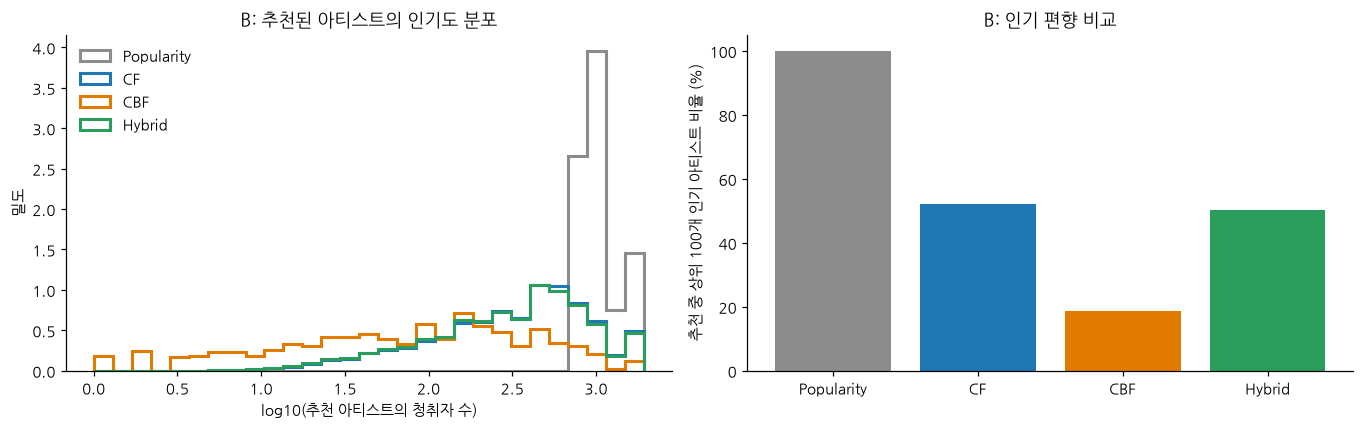

In [72]:
# 5-1. 인기도 분포 · 새로움
for tag, c in CTX.items():
    pop_cnt = c['hist'].groupby('artist_id').user_id.nunique()
    N = c['hist'].user_id.nunique()
    head = set(pop_cnt[pop_cnt.index.isin(c['cand'])].sort_values(ascending=False).index[:100])       # 공통 후보 중 상위 100개 = 헤드
    rows = []
    for m in MODELS:
        recs = c['recs'][[k for k in KEYS if LABEL[k] == m][0]]
        listeners = recs.artist_id.map(pop_cnt).fillna(0)
        rows.append({'model': m, '추천 중 서로 다른 아티스트 수': recs.artist_id.nunique(),
                     '추천 아티스트 청취자 수 중앙값': float(listeners.median()),
                     '헤드(상위100) 비율': float(recs.artist_id.isin(head).mean()),
                     '새로움(평균 -log2((l+1)/(N+1)))': float((-np.log2((listeners + 1) / (N + 1))).mean())})   # CF·CBF 노트북과 같은 정의
    RES[tag]['pop'] = pd.DataFrame(rows).set_index('model')
    print(f'\n[{tag}] 추천 아티스트의 인기도 · 새로움'); display(RES[tag]['pop'].round(3))
    RES[tag]['pop'].round(6).to_csv(OUT / f'table4_{tag}_popularity_novelty.csv')
    fig, axs = plt.subplots(1, 2, figsize=(12.5, 4))
    bins = np.linspace(0, np.log10(max(pop_cnt.max(), 10)) + 0.05, 30)
    for k in KEYS:
        axs[0].hist(np.log10(c['recs'][k].artist_id.map(pop_cnt).fillna(1).clip(lower=1)), bins=bins, histtype='step', lw=2, density=True, color=COLORS[LABEL[k]], label=LABEL[k])
    axs[0].set(xlabel='log10(추천 아티스트의 청취자 수)', ylabel='밀도', title=f'{tag}: 추천된 아티스트의 인기도 분포'); axs[0].legend(frameon=False)
    axs[1].bar(MODELS, RES[tag]['pop']['헤드(상위100) 비율'] * 100, color=[COLORS[m] for m in MODELS])
    axs[1].set(ylabel='추천 중 상위 100개 인기 아티스트 비율 (%)', title=f'{tag}: 인기 편향 비교')
    plt.tight_layout(); plt.savefig(OUT / f'fig3_popularity_distribution_{tag}.png', dpi=160); plt.show()


[A] 청취량 3분위별 NDCG@10


,Popularity,CF,CBF,Hybrid
청취량 적음\n(n=626),0.0505,0.1662,0.1033,0.1763
청취량 중간\n(n=625),0.0866,0.2081,0.1146,0.2125
청취량 많음\n(n=626),0.0979,0.2375,0.1138,0.2397


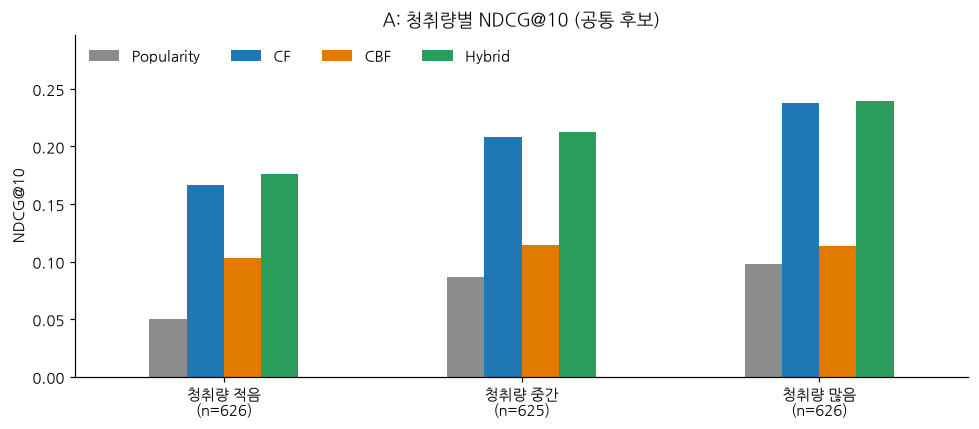


[B] 청취량 3분위별 NDCG@10


,Popularity,CF,CBF,Hybrid
청취량 적음\n(n=3311),0.0330,0.1515,0.0885,0.1580
청취량 중간\n(n=3310),0.0501,0.1691,0.0816,0.1703
청취량 많음\n(n=3310),0.0538,0.1863,0.0842,0.1870


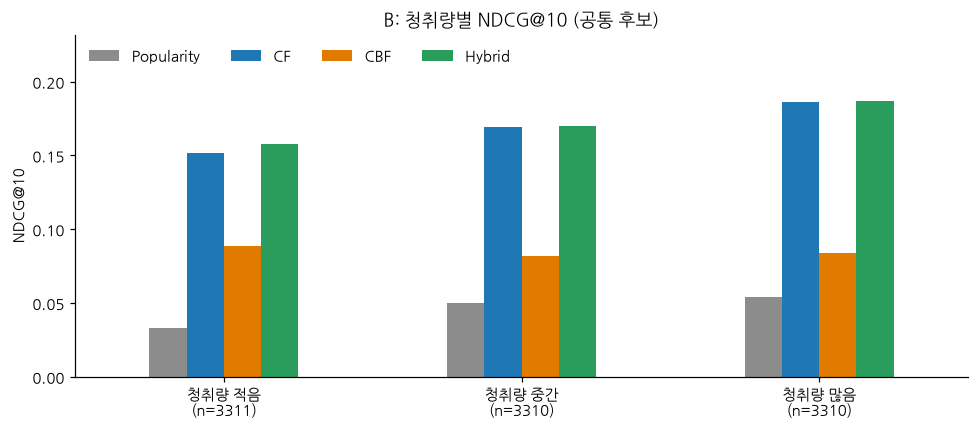

In [73]:
# 5-2. 사용자 청취량별 성능
# 사용자당 관측 아티스트 수는 대부분 같아 구분이 어려우므로, 총 청취 횟수(plays 합)의 3분위로 나눕니다.
for tag, c in CTX.items():
    tot = c['hist'][c['hist'].user_id.isin(c['users'])].groupby('user_id').plays.sum()
    grp = pd.qcut(tot, 3, labels=['적음', '중간', '많음'])
    by = {m: RES[tag]['per'][m].set_index('user_id')[['ndcg10']].join(grp.rename('group')).groupby('group', observed=True).ndcg10.mean() for m in MODELS}
    tg = pd.DataFrame(by)
    tg.index = [f'청취량 {g}\n(n={int((grp == g).sum())})' for g in tg.index]
    RES[tag]['group'] = tg
    print(f'\n[{tag}] 청취량 3분위별 NDCG@10'); display(tg.round(4)); tg.round(6).to_csv(OUT / f'table5_{tag}_by_user_activity.csv')
    ax = tg.plot(kind='bar', figsize=(9, 4), color=[COLORS[m] for m in tg.columns], rot=0)
    ax.set(ylabel='NDCG@10', title=f'{tag}: 청취량별 NDCG@10 (공통 후보)'); ax.set_ylim(0, ax.get_ylim()[1] * 1.18); ax.legend(frameon=False, ncol=4, loc='upper left')
    plt.tight_layout(); plt.savefig(OUT / f'fig4_by_user_activity_{tag}.png', dpi=160); plt.show()

In [74]:
# 5-3. CF · CBF 추천 겹침과 상호 보완성 (하이브리드가 필요한 근거)
for tag, c in CTX.items():
    truth_by = c['truth'].groupby('user_id').artist_id.agg(set).to_dict()
    l_cf = c['recs']['cf'].groupby('user_id').artist_id.agg(set).to_dict(); l_cbf = c['recs']['cbf'].groupby('user_id').artist_id.agg(set).to_dict()
    jac, h_cf, h_cbf, h_both = [], 0, 0, 0
    for u in c['users']:
        x_, y_ = l_cf.get(u, set()), l_cbf.get(u, set()); g = truth_by[u]
        jac.append(len(x_ & y_) / max(len(x_ | y_), 1))
        hx, hy = x_ & g, y_ & g
        h_cf += len(hx - hy); h_cbf += len(hy - hx); h_both += len(hx & hy)
    tot_h = max(h_cf + h_cbf + h_both, 1)
    RES[tag]['overlap'] = {'jaccard_mean': float(np.mean(jac)), 'hits_both': h_both, 'hits_cf_only': h_cf, 'hits_cbf_only': h_cbf, 'share_both': h_both / tot_h, 'share_cf_only': h_cf / tot_h, 'share_cbf_only': h_cbf / tot_h}
    o = RES[tag]['overlap']
    print(f"[{tag}] 추천 목록 Jaccard 평균 {o['jaccard_mean']:.3f} (낮을수록 서로 다른 아티스트 추천)")
    print(f"[{tag}] 적중 아티스트: 둘 다 {o['hits_both']} ({o['share_both']:.1%}) | CF만 {o['hits_cf_only']} ({o['share_cf_only']:.1%}) | CBF만 {o['hits_cbf_only']} ({o['share_cbf_only']:.1%})")

[A] 추천 목록 Jaccard 평균 0.105 (낮을수록 서로 다른 아티스트 추천)
[A] 적중 아티스트: 둘 다 1034 (26.8%) | CF만 2087 (54.0%) | CBF만 742 (19.2%)
[B] 추천 목록 Jaccard 평균 0.105 (낮을수록 서로 다른 아티스트 추천)
[B] 적중 아티스트: 둘 다 3191 (24.3%) | CF만 7556 (57.4%) | CBF만 2406 (18.3%)


## 6. 안정성 (사용자 재표집 반복)
데이터 분할은 seed 42로 한 번만 고정되어 있으므로, 평가 사용자의 80%를 서로 다른 seed로 10번 뽑아 지표가 얼마나 흔들리는지 확인합니다. 결과의 표준편차가 모델 간 차이보다 충분히 작고, 모델 순위(CF > CBF > 인기순, 하이브리드 > CF)가 10회 모두 유지되면 결론이 특정 표본에 의존하지 않는다고 볼 수 있습니다.

In [75]:
# 6-1. 반복 재표집
for tag, c in CTX.items():
    rep = []
    for sd in range(10):
        pick = set(np.random.default_rng(sd).choice(c['users'], int(len(c['users']) * .8), replace=False))
        for m in MODELS:
            d = RES[tag]['per'][m]; d = d[d.user_id.isin(pick)]
            rep.append({'seed': sd, 'model': m, 'precision10': d.precision10.mean(), 'recall10': d.recall10.mean(), 'ndcg10': d.ndcg10.mean()})
    rep = pd.DataFrame(rep)
    stab = rep.groupby('model')[['precision10', 'recall10', 'ndcg10']].agg(['mean', 'std']).reindex(MODELS)
    piv = rep.pivot(index='seed', columns='model', values='ndcg10')
    RES[tag]['stab'] = dict(table=stab, order_ok=bool(((piv.CF > piv.CBF) & (piv.CBF > piv.Popularity)).all()), hyb_gt_cf=int((piv.Hybrid > piv.CF).sum()))
    print(f'\n[{tag}] 재표집 10회 평균·표준편차'); display(stab.round(4)); rep.to_csv(OUT / f'table6_{tag}_repeated_resampling.csv', index=False)
    print(f"10회 모두 CF > CBF > Popularity: {RES[tag]['stab']['order_ok']} | Hybrid > CF: {RES[tag]['stab']['hyb_gt_cf']}/10회")


[A] 재표집 10회 평균·표준편차


precision10         recall10          ndcg10        
                  mean     std     mean     std    mean     std
model                                                          
Popularity      0.0669  0.0008   0.0686  0.0008  0.0786  0.0010
CF              0.1664  0.0017   0.1694  0.0017  0.2043  0.0019
CBF             0.0949  0.0011   0.0968  0.0012  0.1107  0.0012
Hybrid          0.1702  0.0015   0.1734  0.0017  0.2095  0.0021

10회 모두 CF > CBF > Popularity: True | Hybrid > CF: 10/10회

[B] 재표집 10회 평균·표준편차


precision10         recall10          ndcg10        
                  mean     std     mean     std    mean     std
model                                                          
Popularity      0.0314  0.0002   0.0450  0.0003  0.0459  0.0003
CF              0.1085  0.0005   0.1681  0.0008  0.1694  0.0008
CBF             0.0565  0.0004   0.0897  0.0006  0.0850  0.0005
Hybrid          0.1114  0.0006   0.1732  0.0009  0.1722  0.0009

10회 모두 CF > CBF > Popularity: True | Hybrid > CF: 10/10회


## 7. 데이터셋 간 일관성 · 통합 요약
A와 B는 사용자 집단과 후보가 달라 절대값을 비교하지 않습니다. 대신 **모델 순위가 두 데이터셋에서 같은지**만 확인합니다.

In [76]:
# 7-1. 모델 순위 일관성 · 통합 표
rank_rows = []
for tag in CTX:
    T = RES[tag]['tab']
    for m in ['precision10', 'recall10', 'ndcg10', 'catalog_coverage']:
        rank_rows.append({'dataset': tag, 'metric': m, **{n: int(T[m].rank(ascending=False)[n]) for n in MODELS}})
rank_df = pd.DataFrame(rank_rows)
print('[모델 순위] 1 = 가장 높음'); display(rank_df)

final = pd.concat([RES[tag]['tab'].assign(dataset=tag, protocol='common candidates').reset_index() for tag in CTX], ignore_index=True)
final = final[['dataset', 'protocol', 'model'] + cols]
final.round(6).to_csv(OUT / 'final_comparison.csv', index=False)

# 통합 결과표: 공식(우선) 값을 먼저, 공통 후보(보조) 값을 이어서 한 표로 정리
if tab1 is not None:
    off_part = tab1[['dataset', 'model', 'precision10', 'recall10', 'ndcg10', 'catalog_coverage', 'catalog_size', 'users']].copy()
    off_part['dataset'] = off_part.dataset.str.replace('_test', ''); off_part['basis'] = '1. 공식 (모델 노트북 조건, 우선)'
    com_part = final[['dataset', 'model', 'precision10', 'recall10', 'ndcg10', 'catalog_coverage', 'catalog_size', 'users']].copy()
    com_part['basis'] = '2. 공통 후보 (상대 비교용, 보조)'
    integrated = pd.concat([off_part, com_part], ignore_index=True)
    integrated['model'] = pd.Categorical(integrated.model, MODELS, ordered=True)
    integrated = integrated.sort_values(['dataset', 'basis', 'model']).reset_index(drop=True)
    integrated = integrated[['dataset', 'basis', 'model', 'precision10', 'recall10', 'ndcg10', 'catalog_coverage', 'catalog_size', 'users']]
    print('\n[통합 결과표] 공식 결과(우선)와 공통 후보 결과(보조). 하이브리드는 공통 후보 기준으로만 산출됩니다.'); display(integrated.round(4))
    integrated.round(6).to_csv(OUT / 'integrated_results.csv', index=False)
if len(CTX) == 2:
    same_order = list(RES['A']['tab'].ndcg10.sort_values(ascending=False).index) == list(RES['B']['tab'].ndcg10.sort_values(ascending=False).index)
    print('A와 B의 NDCG@10 모델 순위가 같은가:', same_order)

[모델 순위] 1 = 가장 높음


,dataset,metric,Popularity,CF,CBF,Hybrid
0,A,precision10,4,2,3,1
1,A,recall10,4,2,3,1
2,A,ndcg10,4,2,3,1
3,A,catalog_coverage,4,3,1,2
4,B,precision10,4,2,3,1
5,B,recall10,4,2,3,1
6,B,ndcg10,4,2,3,1
7,B,catalog_coverage,4,3,1,2



[통합 결과표] 공식 결과(우선)와 공통 후보 결과(보조). 하이브리드는 공통 후보 기준으로만 산출됩니다.


,dataset,basis,model,precision10,recall10,ndcg10,catalog_coverage,catalog_size,users
0,A,"1. 공식 (모델 노트북 조건, 우선)",Popularity,0.0669,0.0685,0.0783,0.0017,15384,1877
1,A,"1. 공식 (모델 노트북 조건, 우선)",CF,0.1663,0.1692,0.2039,0.0471,15384,1877
2,A,"1. 공식 (모델 노트북 조건, 우선)",CBF,0.0973,0.0992,0.1135,0.2296,10425,1877
3,A,"2. 공통 후보 (상대 비교용, 보조)",Popularity,0.0669,0.0685,0.0783,0.0028,9444,1877
4,A,"2. 공통 후보 (상대 비교용, 보조)",CF,0.1663,0.1692,0.2039,0.0763,9444,1877
5,A,"2. 공통 후보 (상대 비교용, 보조)",CBF,0.0946,0.0965,0.1106,0.2445,9444,1877
6,A,"2. 공통 후보 (상대 비교용, 보조)",Hybrid,0.1701,0.1733,0.2095,0.0840,9444,1877
7,B,"1. 공식 (모델 노트북 조건, 우선)",Popularity,0.0322,0.0342,0.0394,0.0005,48981,9997
8,B,"1. 공식 (모델 노트북 조건, 우선)",CF,0.1165,0.1249,0.1462,0.0645,48981,9997
9,B,"1. 공식 (모델 노트북 조건, 우선)",CBF,0.0554,0.0878,0.0831,0.4011,9282,9931


A와 B의 NDCG@10 모델 순위가 같은가: True


In [77]:
# 7-2. 핵심 결과 자동 요약 (수치는 위 표에서 그대로 가져옴)
def ci_get(tag, x_, y_):
    r = RES[tag]['ci']; r = r[(r['비교'] == f'{x_} − {y_}') & (r['지표'] == 'ndcg10')].iloc[0]; return r
lines = []
if tab1 is not None:
    for ds in ['A_test', 'B_test']:
        t_ = tab1[tab1.dataset == ds]
        if len(t_): lines.append(f"[{ds[0]} · 공식 결과(우선 기준) · NDCG@10] " + ' / '.join(f"{r.model} {r.ndcg10:.4f}" for r in t_.itertuples()))
for tag, c in CTX.items():
    T = RES[tag]['tab']; o = RES[tag]['overlap']; P = RES[tag]['pop']; S = RES[tag]['stab']
    h_cf = ci_get(tag, 'Hybrid', 'CF')
    lines += [
        f"[{tag} · 공통 후보(보조 기준) {len(c['cand']):,}개 · 사용자 {len(c['users']):,}명 · NDCG@10] " + ' / '.join(f'{m} {T.loc[m, "ndcg10"]:.4f}' for m in MODELS),
        f"[{tag} · Coverage] " + ' / '.join(f'{m} {T.loc[m, "catalog_coverage"]:.1%}' for m in MODELS),
        f"[{tag} · 하이브리드] w={HCFG['hybrid']['w_cf']} (A-validation 확정). Hybrid−CF NDCG@10 {h_cf['평균 차이']:+.4f} (95% CI {h_cf['CI 하한']:+.4f}~{h_cf['CI 상한']:+.4f}), 재표집 Hybrid>CF {S['hyb_gt_cf']}/10회",
        f"[{tag} · 인기 편향] 상위100 비율 " + ' / '.join(f'{m} {P.loc[m, "헤드(상위100) 비율"]:.0%}' for m in MODELS),
        f"[{tag} · 보완성] 적중 중 둘 다 {o['share_both']:.1%}, CF만 {o['share_cf_only']:.1%}, CBF만 {o['share_cbf_only']:.1%}; Jaccard 평균 {o['jaccard_mean']:.3f}",
        f"[{tag} · 안정성] 10회 재표집에서 CF>CBF>Popularity 유지: {S['order_ok']}"]
if repro:
    lines.append('[재현성] 저장된 추천 CSV 재평가: ' + ', '.join(f"{k} {'일치' if v else '불일치'}" for k, v in repro.items()))
(OUT / 'summary.txt').write_text('\n'.join(lines), encoding='utf-8')
print('\n'.join(lines)); print('\n저장 위치:', OUT); print('저장된 파일:', sorted(p.name for p in OUT.iterdir()))

[A · 공식 결과(우선 기준) · NDCG@10] Popularity 0.0783 / CF 0.2039 / CBF 0.1135
[B · 공식 결과(우선 기준) · NDCG@10] Popularity 0.0394 / CF 0.1462 / CBF 0.0831
[A · 공통 후보(보조 기준) 9,444개 · 사용자 1,877명 · NDCG@10] Popularity 0.0783 / CF 0.2039 / CBF 0.1106 / Hybrid 0.2095
[A · Coverage] Popularity 0.3% / CF 7.6% / CBF 24.4% / Hybrid 8.4%
[A · 하이브리드] w=0.9 (A-validation 확정). Hybrid−CF NDCG@10 +0.0056 (95% CI +0.0028~+0.0082), 재표집 Hybrid>CF 10/10회
[A · 인기 편향] 상위100 비율 Popularity 100% / CF 74% / CBF 22% / Hybrid 71%
[A · 보완성] 적중 중 둘 다 26.8%, CF만 54.0%, CBF만 19.2%; Jaccard 평균 0.105
[A · 안정성] 10회 재표집에서 CF>CBF>Popularity 유지: True
[B · 공통 후보(보조 기준) 8,161개 · 사용자 9,931명 · NDCG@10] Popularity 0.0456 / CF 0.1690 / CBF 0.0847 / Hybrid 0.1718
[B · Coverage] Popularity 0.3% / CF 30.3% / CBF 43.7% / Hybrid 31.7%
[B · 하이브리드] w=0.9 (A-validation 확정). Hybrid−CF NDCG@10 +0.0028 (95% CI +0.0015~+0.0042), 재표집 Hybrid>CF 10/10회
[B · 인기 편향] 상위100 비율 Popularity 100% / CF 52% / CBF 19% / Hybrid 50%
[B · 보완성] 적중 중 둘 다 24.3%, CF만 57.

## 한계와 해석 시 주의
1. **공통 후보 기준은 CBF가 추천할 수 있는 범위로 모든 모델을 제한한 보조 평가**입니다. CF·인기순은 원래 더 넓은 후보에서 추천할 수 있으므로, 기준 수치는 표 ①(공식)이며 표 ②(공통)는 상대 비교용입니다. 보고할 때는 어느 기준인지 함께 밝혀야 합니다.
2. **B의 정답은 공통 후보로 제한된 정답**입니다. 원본 B 전체 청취 중 후보 밖 아티스트는 정답에서 빠지므로, B 점수는 A와 직접 비교할 수 없습니다. 모델별 공식 B 수치(CF는 B 전체 정답, CBF는 제한된 정답)도 서로 직접 비교할 수 없습니다. 공통 후보 기준의 B CF 수치는 외부 후보 이력으로 다시 계산한 것이므로 CF의 공식 B 수치(CF 노트북 조건)와 다르며, CF의 기준 수치는 공식 값입니다. 하이브리드는 B 전체 조건으로 평가할 수 없어 공통 후보 기준으로만 제시합니다.
3. **하이브리드는 선택 확장**입니다(제안서의 필수 범위 밖). 가중치는 A-validation에서 하나만 골랐고, 공통 후보에서 CF 쪽 가중치가 크게 선택되었으므로 정확도 향상 폭은 CF 대비 작습니다. 다양성(Coverage)을 높이려면 가중치를 낮춰야 하며 정확도와 맞바꿔야 합니다(03 노트북의 가중치 그래프 참고).
4. 신뢰구간은 **평가 사용자 표본에 의한 불확실성**만 반영합니다. 데이터 분할(seed 42 한 번)에 따른 변동은 반영하지 않습니다.
5. 암묵적 피드백이므로 추천되지 않은 아티스트를 "싫어함"으로 해석하지 않습니다.

## 수업에서 다루지 않은 함수·라이브러리 설명
| 함수/기법 | 역할 | 이 노트북에서 쓴 방식 |
|---|---|---|
| Paired bootstrap (Efron, 1979) | 같은 사용자 쌍의 차이를 복원추출해 평균 차이의 신뢰구간 추정 | `paired_bootstrap()`: 2,000회, 2.5%·97.5% 분위수 |
| `np.random.default_rng(seed).integers / choice` | 시드를 고정한 난수 생성 | bootstrap, 재표집 |
| `np.percentile(a, [2.5, 97.5])` | 분위수 계산 | 신뢰구간 경계 |
| `pd.qcut(x, 3, labels=[...])` | 값을 같은 인원의 3구간으로 분할 | 청취량 3분위 그룹 |
| `df.pivot(index, columns, values)` | 긴 표를 넓은 표로 변환 | 반복 재표집 결과를 모델별 열로 정리 |
| `Series.rank(ascending=False)` | 순위 계산 | 모델 순위 일관성 |
| `zipfile.ZipFile(...).open(name)` | ZIP 안의 파일을 압축 해제 없이 읽음 | 전처리 ZIP 로드 |
| `df.groupby(...).agg(['mean','std'])` | 그룹별 여러 통계를 한 번에 계산 | 재표집 평균·표준편차 |
| `matplotlib` `errorbar`, `hist(histtype='step')`, `annotate` | 신뢰구간 막대, 외곽선 히스토그램, 점 라벨 | 그래프 2·3·1 |